# Road Damage and Road Hazard Detection with YOLO26s

This notebook trains one YOLO26s object-detection model on the six-class dataset stored in Google Drive. It performs dataset verification, training, automatic best-checkpoint selection, validation, final testing, metric export, and qualitative prediction visualization.

**Model:** `yolo26s.pt`  
**Classes:** pothole, crack, debris, manhole, speed breaker, road barricade  
**Data source:** Google Drive (images are read directly from Drive)

## 1. Install Ultralytics

In [1]:
%pip install -q -U ultralytics

## 2. Mount Google Drive and check the GPU

In Colab, select **Runtime > Change runtime type > GPU** before running this section.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json
import random
import shutil
import subprocess
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
import yaml
from IPython.display import Image as DisplayImage, display
from ultralytics import YOLO

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('Ultralytics:', ultralytics.__version__)
print('CUDA available:', torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError('No GPU is active. Select Runtime > Change runtime type > GPU.')

print('GPU:', torch.cuda.get_device_name(0))
subprocess.run(['nvidia-smi'], check=False)

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: 3.13.16
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.211
CUDA available: True
GPU: NVIDIA L4


CompletedProcess(args=['nvidia-smi'], returncode=0)

## 3. Locate the dataset and define the experiment

The code accepts either `Final` or `final`, because Colab paths are case-sensitive. Change the candidate paths only if the Drive folder structure is different.

In [3]:
DATASET_CANDIDATES = [
    Path('/content/drive/MyDrive/DIP/Project/Final'),
    Path('/content/drive/MyDrive/DIP/Project/final'),
]

DATASET_DIR = next((path for path in DATASET_CANDIDATES if path.exists()), None)
if DATASET_DIR is None:
    checked = '\n'.join(str(path) for path in DATASET_CANDIDATES)
    raise FileNotFoundError(f'Dataset folder was not found. Checked:\n{checked}')

PROJECT_DIR = DATASET_DIR.parent
RUNS_DIR = PROJECT_DIR / 'runs'
RUNS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_WEIGHTS = 'yolo26s.pt'
RUN_NAME = 'yolo26s_road_damage'
EPOCHS = 60
IMAGE_SIZE = 640
PATIENCE = 15
WORKERS = 2
SEED = 42

CLASS_NAMES = {
    0: 'pothole',
    1: 'crack',
    2: 'debris',
    3: 'manhole',
    4: 'speed_breaker',
    5: 'road_barricade',
}

print('Dataset:', DATASET_DIR)
print('Training outputs:', RUNS_DIR)
print('Model:', MODEL_WEIGHTS)

Dataset: /content/drive/MyDrive/DIP/Project/Final
Training outputs: /content/drive/MyDrive/DIP/Project/runs
Model: yolo26s.pt


## 4. Verify images and labels

This recursively checks all `part_###` subfolders, confirms that all three splits exist, and verifies that image and label relative paths match. It does not modify the dataset. The subfolder layout keeps every Google Drive directory below the large-directory item limit.

In [4]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
EXPECTED_COUNTS = {
    'train': 40468,
    'valid': 7303,
    'test': 4563,
}

dataset_rows = []
for split in ('train', 'valid', 'test'):
    image_dir = DATASET_DIR / 'images' / split
    label_dir = DATASET_DIR / 'labels' / split

    if not image_dir.is_dir() or not label_dir.is_dir():
        raise FileNotFoundError(f'Missing images or labels directory for split: {split}')

    image_paths = [p for p in image_dir.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
    label_paths = [p for p in label_dir.rglob('*.txt') if p.is_file()]
    image_keys = {p.relative_to(image_dir).with_suffix('').as_posix() for p in image_paths}
    label_keys = {p.relative_to(label_dir).with_suffix('').as_posix() for p in label_paths}
    missing_labels = image_keys - label_keys
    orphan_labels = label_keys - image_keys

    dataset_rows.append({
        'split': split,
        'images': len(image_paths),
        'labels': len(label_paths),
        'missing_labels': len(missing_labels),
        'orphan_labels': len(orphan_labels),
        'expected_images': EXPECTED_COUNTS[split],
    })

dataset_summary = pd.DataFrame(dataset_rows)
display(dataset_summary)

if dataset_summary['images'].sum() == 0:
    raise RuntimeError('No images were found.')
if dataset_summary['missing_labels'].sum() or dataset_summary['orphan_labels'].sum():
    raise RuntimeError('Image/label basename mismatches were found.')

for row in dataset_rows:
    if row['images'] != row['expected_images']:
        print(f"Warning: {row['split']} contains {row['images']} images; expected {row['expected_images']}.")

print('Dataset verification completed successfully.')

,split,images,labels,missing_labels,orphan_labels,expected_images
0,train,40468,40468,0,0,40468
1,valid,7303,7303,0,0,7303
2,test,4563,4563,0,0,4563


Dataset verification completed successfully.


## 5. Create a Colab-specific dataset YAML

A separate `data_colab.yaml` is created so the original local `data.yaml` does not need to be changed.

In [5]:
DATA_YAML = DATASET_DIR / 'data_colab.yaml'
data_config = {
    'path': str(DATASET_DIR),
    'train': 'images/train',
    'val': 'images/valid',
    'test': 'images/test',
    'names': CLASS_NAMES,
}

with DATA_YAML.open('w', encoding='utf-8') as file:
    yaml.safe_dump(data_config, file, sort_keys=False, allow_unicode=True)

print(DATA_YAML.read_text(encoding='utf-8'))

path: /content/drive/MyDrive/DIP/Project/Final
train: images/train
val: images/valid
test: images/test
names:
  0: pothole
  1: crack
  2: debris
  3: manhole
  4: speed_breaker
  5: road_barricade



## 6. Train YOLO26s

Validation runs automatically after each epoch. Ultralytics automatically saves `best.pt` when validation performance improves and `last.pt` at the latest epoch. `batch=-1` selects a batch size based on available GPU memory.

Because the images are read directly from Google Drive, the first epoch may be slower.

In [6]:
model = YOLO(MODEL_WEIGHTS)

train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=-1,
    device=0,
    workers=WORKERS,
    patience=PATIENCE,
    pretrained=True,
    amp=True,
    val=True,
    plots=True,
    save=True,
    save_period=5,
    cache=False,
    seed=SEED,
    deterministic=True,
    project=str(RUNS_DIR),
    name=RUN_NAME,
)

RUN_DIR = Path(model.trainer.save_dir)
BEST_MODEL_PATH = RUN_DIR / 'weights' / 'best.pt'
LAST_MODEL_PATH = RUN_DIR / 'weights' / 'last.pt'

print('Run directory:', RUN_DIR)
print('Best checkpoint:', BEST_MODEL_PATH)
print('Last checkpoint:', LAST_MODEL_PATH)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DIP/Project/Final/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_road_damage, nbs=64, n

## 7. Optional: resume an interrupted training run

Run this section only after a Colab interruption. It finds the newest `last.pt` for this experiment and restores the optimizer, learning-rate schedule, and completed epoch count. Set `RESUME_TRAINING = True` before running it.

In [7]:
RESUME_TRAINING = False

if RESUME_TRAINING:
    last_candidates = list(RUNS_DIR.glob(f'{RUN_NAME}*/weights/last.pt'))
    if not last_candidates:
        raise FileNotFoundError(f'No last.pt checkpoint was found under {RUNS_DIR}.')

    resume_path = max(last_candidates, key=lambda path: path.stat().st_mtime)
    print('Resuming from:', resume_path)
    resume_model = YOLO(str(resume_path))
    resume_model.train(resume=True)
else:
    print('Resume is disabled. Set RESUME_TRAINING = True only after an interruption.')

Resume is disabled. Set RESUME_TRAINING = True only after an interruption.


## 8. Locate and load the automatically selected best model

This cell also works after reconnecting to a fresh Colab runtime. It locates the most recently modified `best.pt` associated with the experiment name.

In [8]:
best_candidates = list(RUNS_DIR.glob(f'{RUN_NAME}*/weights/best.pt'))
if not best_candidates:
    raise FileNotFoundError(f'No best.pt checkpoint was found under {RUNS_DIR}.')

BEST_MODEL_PATH = max(best_candidates, key=lambda path: path.stat().st_mtime)
RUN_DIR = BEST_MODEL_PATH.parent.parent
best_model = YOLO(str(BEST_MODEL_PATH))

print('Selected run:', RUN_DIR)
print('Selected checkpoint:', BEST_MODEL_PATH)
print('Class names:', best_model.names)

Selected run: /content/drive/MyDrive/DIP/Project/runs/yolo26s_road_damage
Selected checkpoint: /content/drive/MyDrive/DIP/Project/runs/yolo26s_road_damage/weights/best.pt
Class names: {0: 'pothole', 1: 'crack', 2: 'debris', 3: 'manhole', 4: 'speed_breaker', 5: 'road_barricade'}


## 9. Display training curves

The figures are loaded from Google Drive and can be used in the final report.

results.png


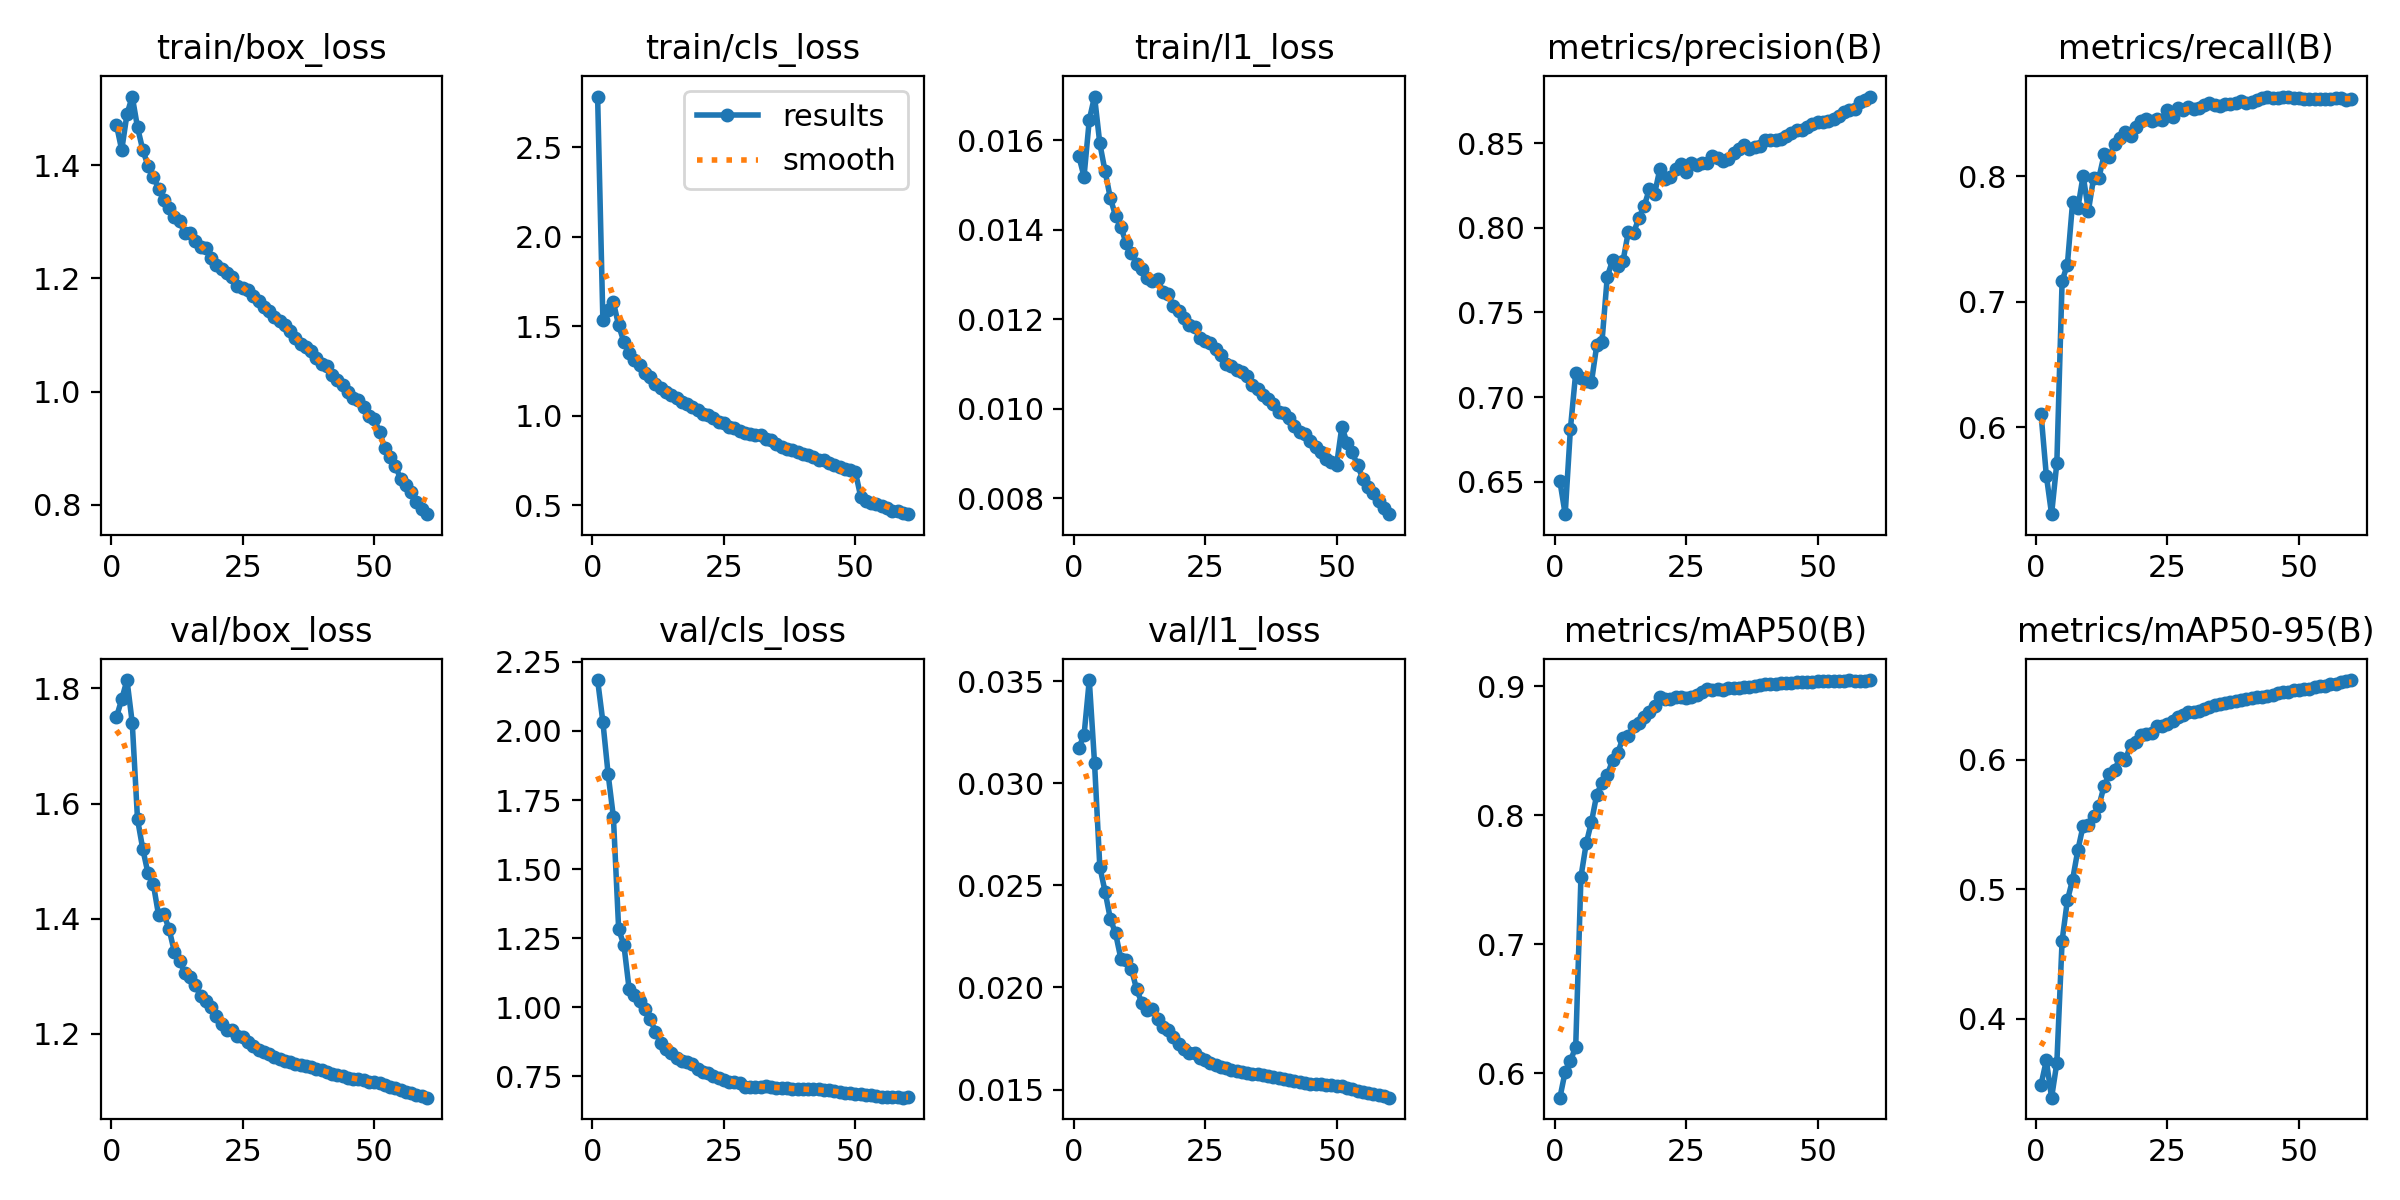

confusion_matrix.png


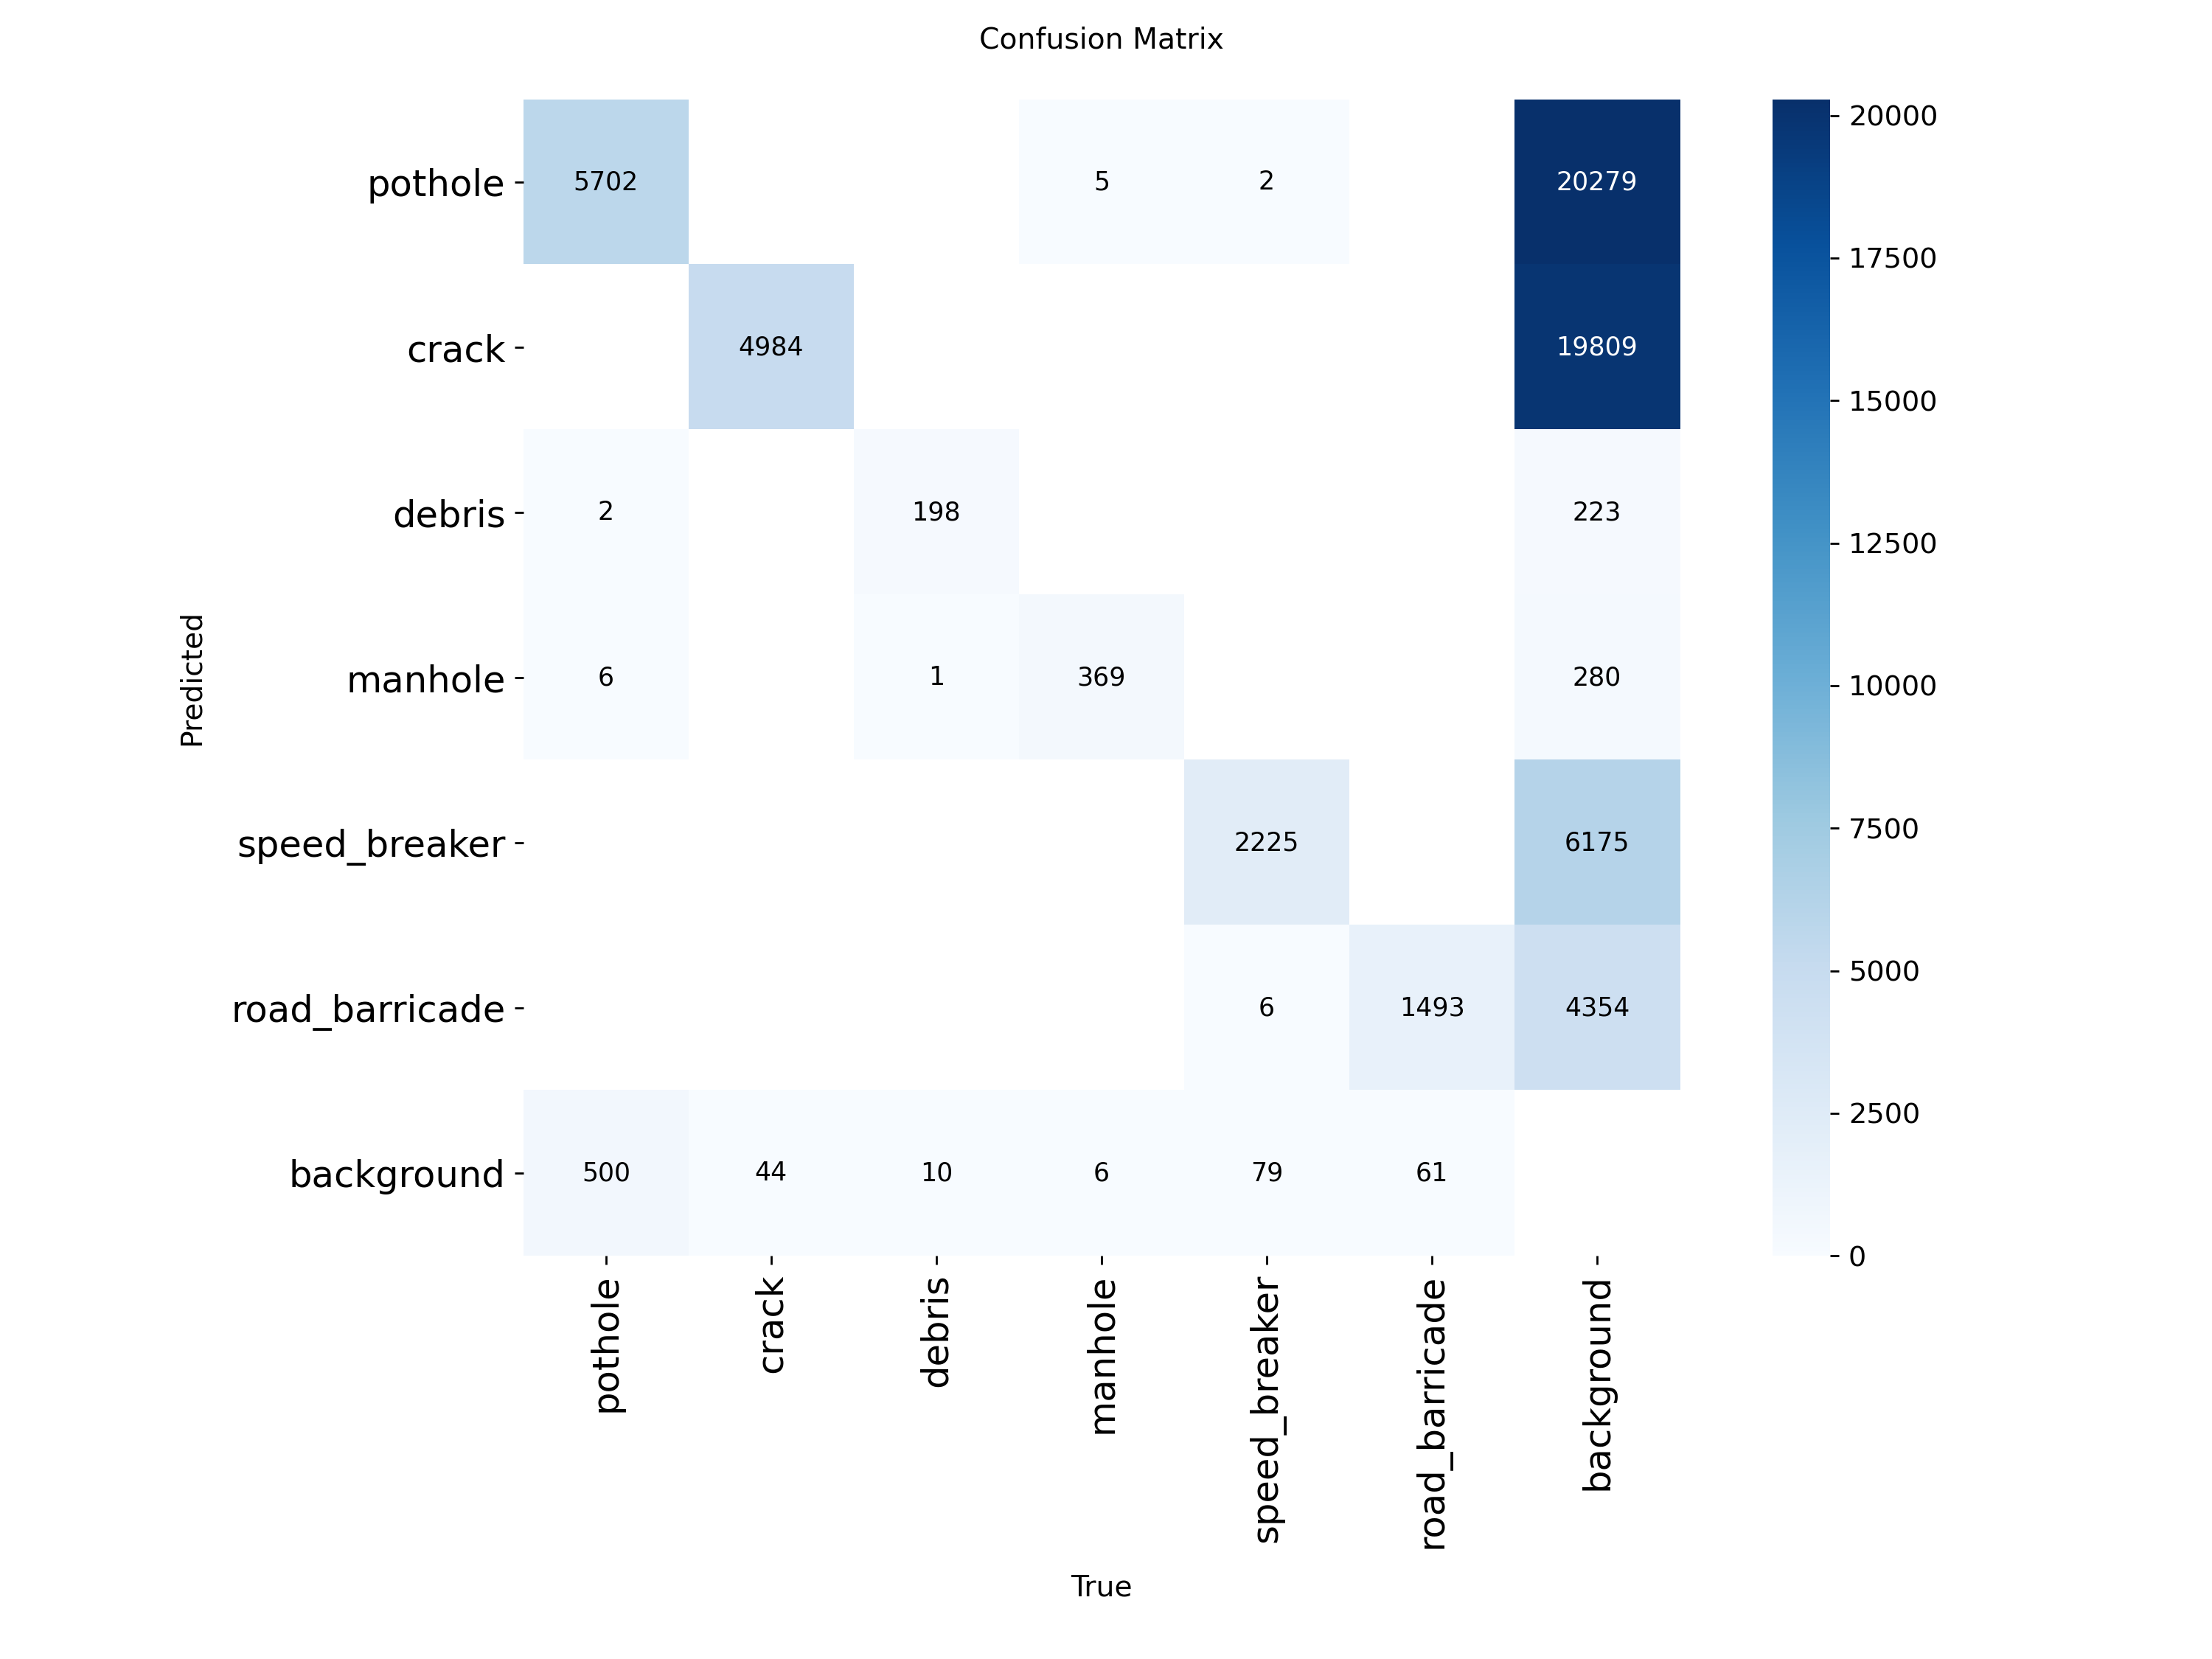

confusion_matrix_normalized.png


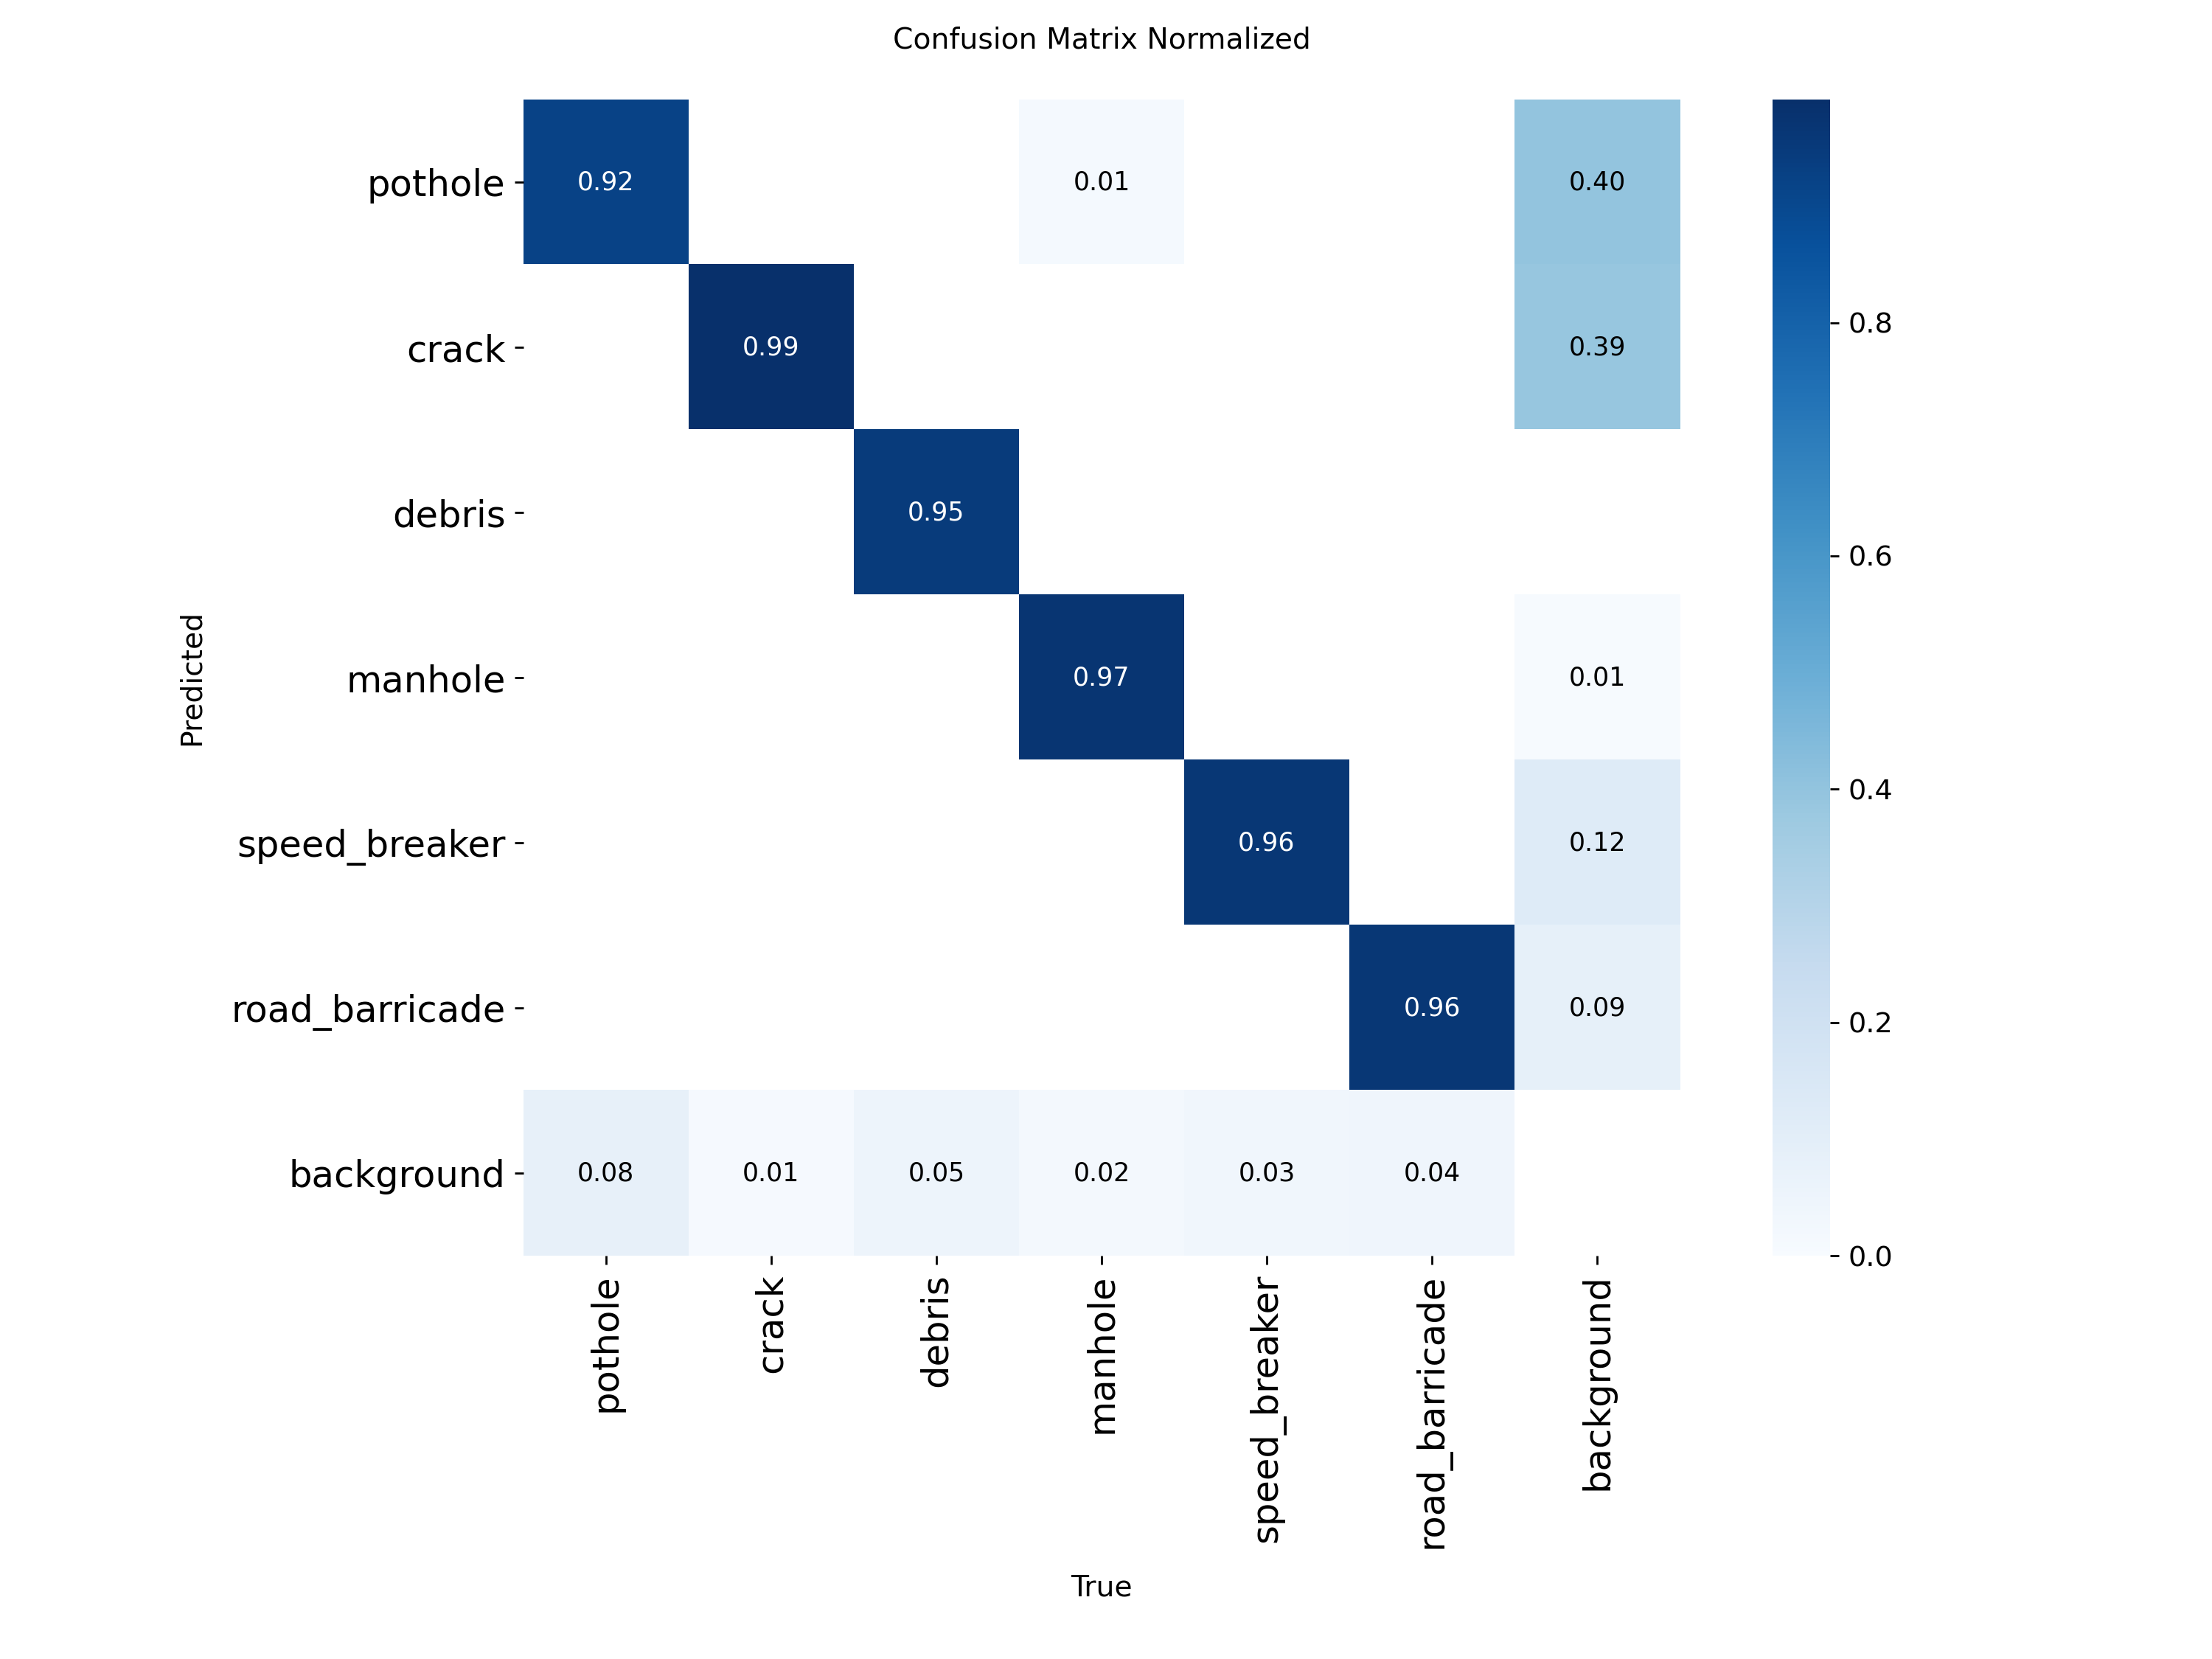

In [9]:
training_figures = [
    'results.png',
    'confusion_matrix.png',
    'confusion_matrix_normalized.png',
    'PR_curve.png',
    'F1_curve.png',
    'P_curve.png',
    'R_curve.png',
]

for filename in training_figures:
    figure_path = RUN_DIR / filename
    if figure_path.exists():
        print(filename)
        display(DisplayImage(filename=str(figure_path)))

## 10. Final validation using `best.pt`

The validation split was used during training to select `best.pt`. This final pass records the complete validation metrics and plots for that checkpoint.

In [10]:
validation_name = f'{RUN_DIR.name}_validation'
val_metrics = best_model.val(
    data=str(DATA_YAML),
    split='val',
    imgsz=IMAGE_SIZE,
    batch=16,
    device=0,
    workers=WORKERS,
    plots=True,
    project=str(RUNS_DIR),
    name=validation_name,
    exist_ok=True,
)

print(f'Validation Precision: {val_metrics.box.mp:.4f}')
print(f'Validation Recall: {val_metrics.box.mr:.4f}')
print(f'Validation mAP50: {val_metrics.box.map50:.4f}')
print(f'Validation mAP50-95: {val_metrics.box.map:.4f}')

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 60.3±37.8 MB/s, size: 65.8 KB)
val: Scanning /content/drive/MyDrive/DIP/Project/Final/labels/valid/part_001.cache... 7303 images, 49 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 7303/7303 2.0Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 457/457 7.4it/s 1:02
                   all       7303      15693      0.877      0.861      0.905      0.661
               pothole       2440       6210      0.867      0.812      0.857      0.595
                 crack       1389       5028      0.785      0.699      0.831      0.513
                debris        209        209      0.911      0.928      0.921      0.775
               manhole        332        380      0.901      0.942      0.968      0.764
        

## 11. Final test evaluation

The test set is evaluated only after training and model selection are complete.

In [11]:
test_name = f'{RUN_DIR.name}_test'
test_metrics = best_model.val(
    data=str(DATA_YAML),
    split='test',
    imgsz=IMAGE_SIZE,
    batch=16,
    device=0,
    workers=WORKERS,
    plots=True,
    project=str(RUNS_DIR),
    name=test_name,
    exist_ok=True,
)

print(f'Test Precision: {test_metrics.box.mp:.4f}')
print(f'Test Recall: {test_metrics.box.mr:.4f}')
print(f'Test mAP50: {test_metrics.box.map50:.4f}')
print(f'Test mAP50-95: {test_metrics.box.map:.4f}')

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 0.1±0.0 MB/s, size: 61.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/DIP/Project/Final/labels/test/part_001... 4563 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4563/4563 8.4it/s 9:04
val: New cache created: /content/drive/MyDrive/DIP/Project/Final/labels/test/part_001.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 286/286 7.6it/s 37.5s
                   all       4563       8376      0.885      0.859      0.912      0.684
               pothole       1148       2708      0.835      0.818      0.849      0.582
                 crack       1390    

## 12. Summarize and save metrics

The summary includes overall metrics and per-class mAP50-95 for both validation and test splits.

In [12]:
def metric_summary(metrics, split_name):
    per_class_maps = np.asarray(metrics.box.maps, dtype=float)
    return {
        'split': split_name,
        'precision': float(metrics.box.mp),
        'recall': float(metrics.box.mr),
        'mAP50': float(metrics.box.map50),
        'mAP50_95': float(metrics.box.map),
        'per_class_mAP50_95': {
            best_model.names[index]: float(per_class_maps[index])
            for index in range(len(per_class_maps))
        },
    }

summary = {
    'model': MODEL_WEIGHTS,
    'best_checkpoint': str(BEST_MODEL_PATH),
    'image_size': IMAGE_SIZE,
    'validation': metric_summary(val_metrics, 'validation'),
    'test': metric_summary(test_metrics, 'test'),
}

METRICS_JSON = RUN_DIR / 'final_metrics.json'
METRICS_JSON.write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(json.dumps(summary, indent=2))
print('Saved:', METRICS_JSON)

{
  "model": "yolo26s.pt",
  "best_checkpoint": "/content/drive/MyDrive/DIP/Project/runs/yolo26s_road_damage/weights/best.pt",
  "image_size": 640,
  "validation": {
    "split": "validation",
    "precision": 0.877142041255094,
    "recall": 0.8609283104967735,
    "mAP50": 0.9045385777218097,
    "mAP50_95": 0.6612288365036129,
    "per_class_mAP50_95": {
      "pothole": 0.5951263495701056,
      "crack": 0.5130437070639988,
      "debris": 0.7745963313585024,
      "manhole": 0.7636432183493135,
      "speed_breaker": 0.5771882279336209,
      "road_barricade": 0.7437751847461356
    }
  },
  "test": {
    "split": "test",
    "precision": 0.8848113019371756,
    "recall": 0.8588088561849986,
    "mAP50": 0.9115633526661725,
    "mAP50_95": 0.6838853348949276,
    "per_class_mAP50_95": {
      "pothole": 0.5823719109027203,
      "crack": 0.6190994643847123,
      "debris": 0.7903692856802397,
      "manhole": 0.8219896389347354,
      "speed_breaker": 0.5582016498982851,
      "ro

## 13. Visualize predictions on random test images

These predictions use the automatically selected `best.pt` checkpoint. Change `CONFIDENCE_THRESHOLD` only if a different operating threshold is required for the final demonstration.

Results saved to /content/drive/MyDrive/DIP/Project/runs/yolo26s_road_damage_test_predictions


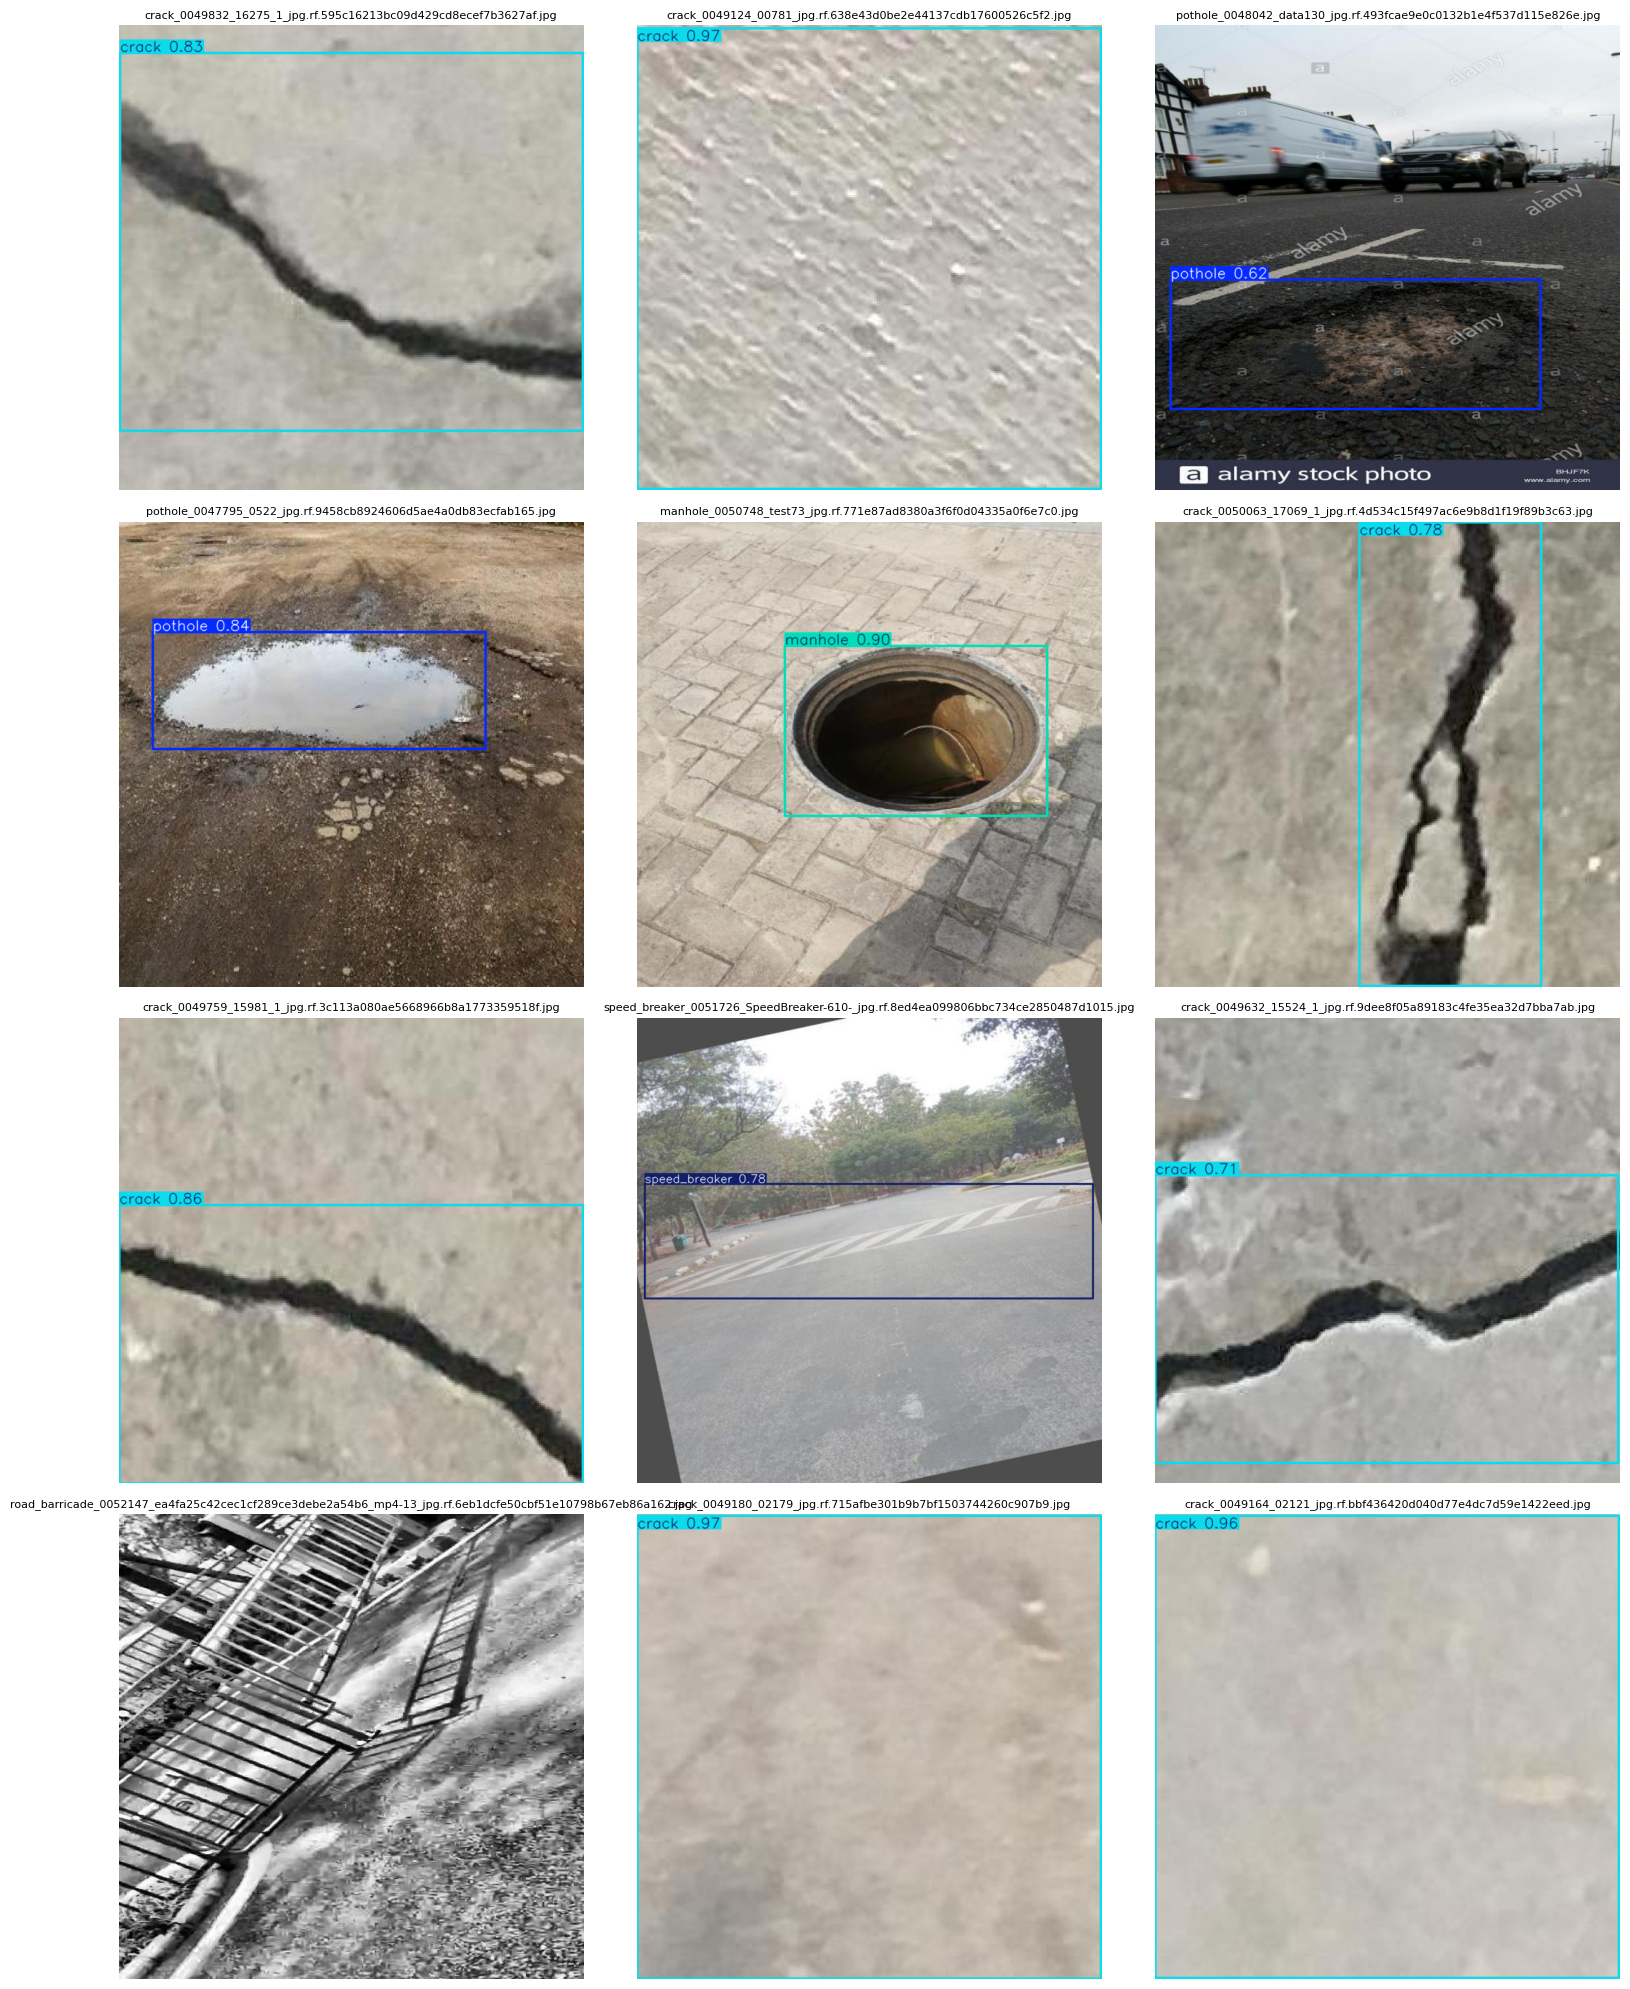

Saved prediction images to: /content/drive/MyDrive/DIP/Project/runs/yolo26s_road_damage_test_predictions


In [13]:
CONFIDENCE_THRESHOLD = 0.25
NUMBER_OF_EXAMPLES = 12

test_image_paths = sorted(
    path for path in (DATASET_DIR / 'images' / 'test').rglob('*')
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)
sample_count = min(NUMBER_OF_EXAMPLES, len(test_image_paths))
sample_paths = random.Random(SEED).sample(test_image_paths, sample_count)

prediction_name = f'{RUN_DIR.name}_test_predictions'
prediction_results = best_model.predict(
    source=[str(path) for path in sample_paths],
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE_THRESHOLD,
    device=0,
    save=True,
    project=str(RUNS_DIR),
    name=prediction_name,
    exist_ok=True,
    verbose=False,
)

columns = 3
rows = int(np.ceil(sample_count / columns))
fig, axes = plt.subplots(rows, columns, figsize=(16, 5 * rows))
axes = np.atleast_1d(axes).ravel()

for axis, result in zip(axes, prediction_results):
    plotted_bgr = result.plot()
    plotted_rgb = cv2.cvtColor(plotted_bgr, cv2.COLOR_BGR2RGB)
    axis.imshow(plotted_rgb)
    axis.set_title(Path(result.path).name, fontsize=8)
    axis.axis('off')

for axis in axes[len(prediction_results):]:
    axis.axis('off')

plt.tight_layout()
plt.show()
print('Saved prediction images to:', RUNS_DIR / prediction_name)

## 14. Optional model export

The PyTorch `best.pt` file is sufficient for this project. Set `EXPORT_ONNX = True` only if an ONNX deployment artifact is also required.

In [14]:
EXPORT_ONNX = False

if EXPORT_ONNX:
    exported_path = best_model.export(
        format='onnx',
        imgsz=IMAGE_SIZE,
        simplify=True,
    )
    print('Exported model:', exported_path)
else:
    print('ONNX export skipped. Set EXPORT_ONNX = True to enable it.')

ONNX export skipped. Set EXPORT_ONNX = True to enable it.


## Final outputs

The main experiment folder under `MyDrive/DIP/Project/runs/` contains:

- `weights/best.pt` — automatically selected best validation checkpoint
- `weights/last.pt` — latest training checkpoint for resuming
- `results.csv` and `results.png` — epoch-by-epoch training history
- confusion matrices and precision/recall/F1 curves
- `final_metrics.json` — validation, test, and per-class metrics
- separate validation, test, and qualitative prediction folders